In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

In [2]:
np.random.seed(42)

N = 50

mu_true = 0
sigma_true = 2

data = np.random.normal(
    mu_true,
    sigma_true,
    N
)

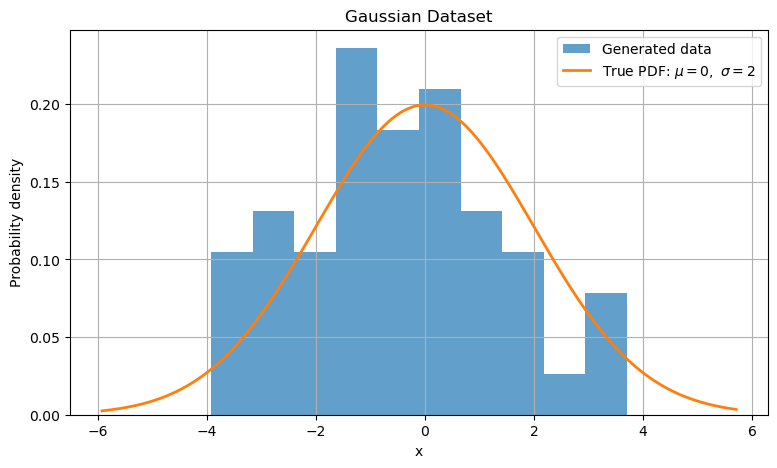

In [3]:
plt.figure(figsize=(9, 5))

plt.hist(
    data,
    bins=10,
    density=True,
    alpha=0.7,
    label='Generated data'
)

x_plot = np.linspace(
    data.min() - 2,
    data.max() + 2,
    500
)

plt.plot(
    x_plot,
    norm.pdf(x_plot, mu_true, sigma_true),
    linewidth=2,
    label=r'True PDF: $\mu=0,\ \sigma=2$'
)

plt.xlabel('x')
plt.ylabel('Probability density')
plt.title('Gaussian Dataset')
plt.legend()
plt.grid(True)

plt.show()

In [24]:
mu_mle = np.mean(data)

sigma_mle = np.sqrt(
    np.mean((data - mu_mle)**2)
)

print(f"True mu     = {mu_true:.4f}")
print(f"MLE mu      = {mu_mle:.4f}")

print(f"True sigma  = {sigma_true:.4f}")
print(f"MLE sigma   = {sigma_mle:.4f}")

True mu     = 0.0000
MLE mu      = -0.4509
True sigma  = 2.0000
MLE sigma   = 1.8486


In [25]:
def log_likelihood(mu, sigma, data):

    if sigma <= 0:
        return -np.inf

    N = len(data)

    return (
        -N * np.log(sigma)
        -0.5 * N * np.log(2 * np.pi)
        -np.sum((data - mu)**2) / (2 * sigma**2)
    )

In [26]:
mu_values = np.linspace(-1.5, 1.5, 200)

sigma_values = np.linspace(1.0, 3.5, 200)

logL_grid = np.zeros(
    (len(sigma_values), len(mu_values))
)

In [27]:
for i, sigma in enumerate(sigma_values):

    for j, mu in enumerate(mu_values):

        logL_grid[i, j] = log_likelihood(
            mu,
            sigma,
            data
        )

In [30]:
max_index = np.unravel_index(
    np.argmax(logL_grid),
    logL_grid.shape
)

sigma_scan = sigma_values[max_index[0]]
mu_scan = mu_values[max_index[1]]

max_logL = logL_grid[max_index]

print(f"True parameters:")
print(f"mu = {mu_true}")
print(f"sigma = {sigma_true}")


print("\nMLE from likelihood scan:")
print(f"mu = {mu_scan:.4f}")
print(f"sigma = {sigma_scan:.4f}")

print(f"\nMaximum log L = {max_logL:.4f}")

True parameters:
mu = 0
sigma = 2

MLE from likelihood scan:
mu = -0.4447
sigma = 1.8543

Maximum log L = -101.6683


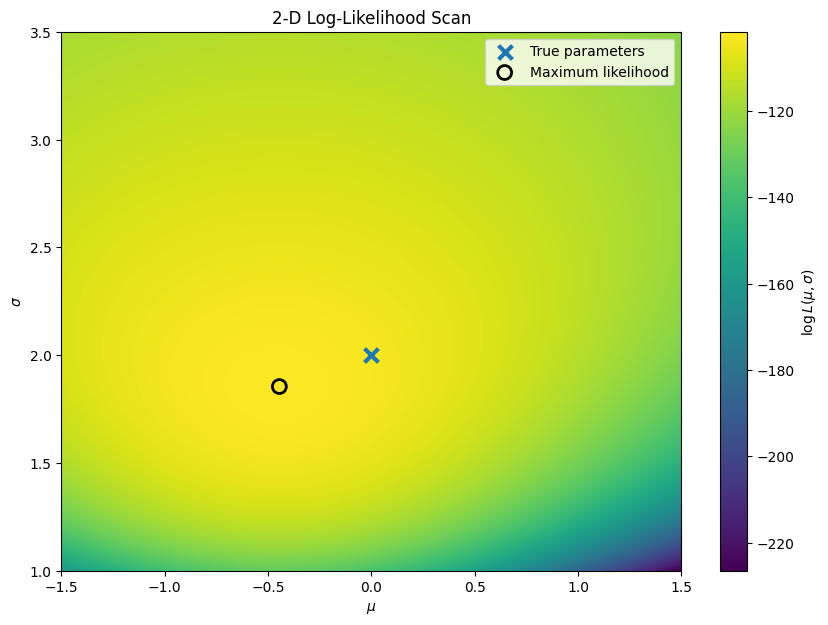

In [31]:
plt.figure(figsize=(10, 7))

plt.imshow(
    logL_grid,
    origin='lower',
    aspect='auto',
    extent=[
        mu_values.min(),
        mu_values.max(),
        sigma_values.min(),
        sigma_values.max()
    ]
)

plt.colorbar(
    label=r'$\log L(\mu,\sigma)$'
)

plt.scatter(
    mu_true,
    sigma_true,
    marker='x',
    s=100,
    linewidths=3,
    label='True parameters'
)

plt.scatter(
    mu_scan,
    sigma_scan,
    marker='o',
    facecolors='none',
    edgecolors='black',
    s=100,
    linewidths=2,
    label='Maximum likelihood'
)

plt.xlabel(r'$\mu$')
plt.ylabel(r'$\sigma$')
plt.title(r'2-D Log-Likelihood Scan')
plt.legend()

plt.show()

In [4]:
import ROOT

print(ROOT.__version__)

6.36.06
